# Anatomical and functional roles of ICs (PASSED QC)

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# project PATH
DATASET_NAME = "sz_meditation"
project_path_str="/scratch/repo_"+DATASET_NAME
project_path= Path(project_path_str)
sys.path.append(str(project_path))

# importing private libs and functions (imaging_arsenal version, need to import the parent dir as well)
private_lib_path = Path('/scratch/imaging_arsenal')
sys.path.append(str(private_lib_path))
sys.path.append(str(private_lib_path / 'utils_'))
print('private lib ready:',(private_lib_path / 'utils_private.py').exists())
from utils_.utils_private import report_cpu
report_cpu()

# data path
data_path = project_path / 'data' 
fig_path = project_path / 'fig' 

# data
basic_time_Tag = "20240724"
all_DKT_path = data_path / (DATASET_NAME+'_R_'+basic_time_Tag+'.csv')
traj_data_path = data_path / "trajectory_class2_20240730.csv"

# read data
all_df = pd.read_csv(all_DKT_path, index_col= None)
tmp_df=all_df.copy()

private lib ready: False


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Total CPUs: 12
Total Memory: 29.38 GB
Available Memory: 16.51 GB


In [2]:
# report major software version
import statsmodels 
import nilearn
import sys
import sklearn
import semopy
import seaborn as sns
import networkx as nx
# setup random seed
rand_seed = 24
np.random.seed(rand_seed)

print('python version:', sys.version)
print('numpy version:', np.__version__)
print('statsmodels version:', statsmodels.__version__)
print('nilearn version:', nilearn.__version__)
print('sklearn version:', sklearn.__version__)
print('semopy version:', semopy.__version__)
print('networkX version:', nx.__version__)
print('seaborn version:', sns.__version__)
print('random seed:', rand_seed)

python version: 3.9.12 | packaged by conda-forge | (main, Mar 24 2022, 23:25:59) 
[GCC 10.3.0]
numpy version: 1.26.4
statsmodels version: 0.14.5
nilearn version: 0.12.0
sklearn version: 1.4.2
semopy version: 2.3.11
networkX version: 3.1
seaborn version: 0.13.2
random seed: 24


In [3]:
## Read atlas and ICmaps info
from nilearn import datasets, input_data, plotting
import nilearn.image as image
import nibabel as nib
import matplotlib.pyplot as plt
#
from utils_.utils_private import plot_all_ICs, read_pkl, save_pkl

derivative_path = Path( "/scratch/"+DATASET_NAME+"/derivatives")
# MNI template
mni152_template = datasets.load_mni152_template()

## read IC results
ICA_time = "20260701"
ICs_file  = derivative_path / ("results_"+ICA_time) / "canICA_038_noGSR"  / 'method-canICA_ses-038_task-rs_desc-noGSR_ICmaps.nii.gz'
ICA_img   = nib.load(ICs_file)

valid_ic_index = [0, 2, 4, 5, 9, 15, 16, 18, 19]
valic_ic_dict = {}

/tmp/ipykernel_96298/1894933750.py:2: DeprecationWarning: The import path 'nilearn.input_data' is deprecated in version 0.9. Importing from 'nilearn.input_data' will be possible at least until release 0.13.0. Please import from 'nilearn.maskers' instead.
  from nilearn import datasets, input_data, plotting


In [4]:
# %% the formal display names together for copying into other notebooks.
# Method: anatomy plus qualified atlas affiliation; output: reusable naming dictionaries.
node_names = {
    'IC00_SMN': 'SMN',
    'IC02_SalVentA': 'SMG–VAN',
    'IC04_Vis_V1': 'mVIS',
    'IC05_aDMN': 'mPFC–DMN',
    'IC09_pDMN': 'PCu–DMN',
    'IC15_DAN': 'SPL–DAN',
    'IC16_FPCN': 'rIPL–FPN',
    'IC18_SalVentB': 'MFG–VAN/FPN',
    'IC19_ECN': 'lIFG–FPN',
}

# Full anatomical name, functional affiliation, and interpretation qualification.
ic_info = {
    'IC00_SMN': ('Perirolandic sensorimotor component', 'Somatomotor',
                 'Bilateral precentral and postcentral anchor.'),
    'IC02_SalVentA': ('Supramarginal-centred ventral-attention component',
                     'Ventral attention with a mixed frontal extension',
                     'Opposite-signed frontal extension; the compact label describes the dominant anchor.'),
    'IC04_Vis_V1': ('Medial visual component', 'Visual',
                    'Medial occipital anchor; not restricted to primary visual cortex.'),
    'IC05_aDMN': ('Medial prefrontal default-mode component', 'Default mode',
                  'Predominantly medial superior frontal anatomy.'),
    'IC09_pDMN': ('Precuneus default-mode component', 'Default mode with frontoparietal overlap',
                  'Predominant default affiliation with mixed frontoparietal overlap.'),
    'IC15_DAN': ('Superior-parietal dorsal-attention component', 'Dorsal attention',
                 'Bilateral superior parietal and precuneus anchor.'),
    'IC16_FPCN': ('Right inferior-parietal frontoparietal component',
                  'Frontoparietal with default-mode overlap',
                  'Right inferior parietal and angular anchor with mixed default overlap.'),
    'IC18_SalVentB': ('Bilateral middle-frontal ventral-attention/frontoparietal component',
                      'Mixed ventral attention and frontoparietal',
                      'The leading network changes with support threshold; retain both affiliations.'),
    'IC19_ECN': ('Left inferior-frontal frontoparietal component', 'Frontoparietal',
                 'Predominantly left inferior frontal triangular and opercular anatomy.'),
}
network_taxonomy = {
    int(node[2:4]): {'node_id': node, 'short': name, 'full': ic_info[node][0],
                     'affiliation': ic_info[node][1], 'note': ic_info[node][2]}
    for node, name in node_names.items()
}

## 1. Intepreting IC by the coverage of classical atlas (Yeo and AAL)

In [5]:
from pathlib import Path
import os
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import nibabel as nib
from nilearn import image, plotting
from IPython.display import display

save_tab = 1
ic_output_dir = data_path / 'Section3_IC_naming'
ic_output_dir.mkdir(parents=True, exist_ok=True)

# default atlas cache for nilearn, fetch atlas to get these files
#yeo = datasets.fetch_atlas_yeo_2011()
#aal = datasets.fetch_atlas_aal()
# #atlas_cache = Path.home() / 'nilearn_data'
#yeo_dir = atlas_cache / 'yeo_2011' / 'Yeo_JNeurophysiol11_MNI152'
#aal_dir = atlas_cache / 'aal_SPM12' / 'aal' / 'atlas'


valic_ic_dict = {i: image.index_img(ICA_img, i) for i in valid_ic_index}
ref_img = valic_ic_dict[valid_ic_index[0]]
yeo7_names = {1: 'Visual', 2: 'Somatomotor', 3: 'Dorsal attention',
              4: 'Ventral attention', 5: 'Limbic', 6: 'Frontoparietal', 7: 'Default'}

atlas_data = {
    'Yeo7': datasets.fetch_atlas_yeo_2011(n_networks=7, thickness='thick'),
    'Yeo17': datasets.fetch_atlas_yeo_2011(n_networks=17, thickness='thick'),
    'AAL_SPM12': datasets.fetch_atlas_aal(version='SPM12'),
}
label_sources = {
    'Yeo7': "nilearn.datasets.fetch_atlas_yeo_2011(n_networks=7, thickness='thick').lut",
    'Yeo17': "nilearn.datasets.fetch_atlas_yeo_2011(n_networks=17, thickness='thick').lut",
    'AAL_SPM12': "nilearn.datasets.fetch_atlas_aal(version='SPM12').lut",
}

atlases = {}
for atlas_name, atlas in atlas_data.items():
    lut = atlas.lut.loc[atlas.lut['index'] > 0, ['index', 'name']]
    labels = dict(zip(lut['index'].astype(int), lut['name'].astype(str)))
    atlas_img = nib.squeeze_image(image.load_img(atlas.maps))
    aligned = image.resample_to_img(atlas_img, ref_img, interpolation='nearest',
                                     force_resample=True, copy_header=True)
    values = np.rint(aligned.get_fdata()).astype(int)
    counts = np.bincount(values.ravel(), minlength=max(labels) + 1)
    atlases[atlas_name] = (values, counts, labels, atlas.maps,
                           label_sources[atlas_name], atlas.template)

# %% Block 4b: Calculate the atlas evidence directly from the IC maps, without reading a CSV.
# Method: all nonzero, top 25% and top 10% absolute loadings, separated by sign; output: overlap CSV.
overlap_rows = []
for i, ic_img in valic_ic_dict.items():
    values = ic_img.get_fdata()
    abs_values = np.abs(values)
    nonzero = abs_values[abs_values > 0]
    cutoffs = {'nonzero': 0.0, 'top25_abs_nonzero': np.percentile(nonzero, 75),
               'top10_abs_nonzero': np.percentile(nonzero, 90)}
    for support, cutoff in cutoffs.items():
        keep = (abs_values > 0) & (abs_values >= cutoff)
        for polarity, mask in [('absolute', keep), ('positive', keep & (values > 0)),
                               ('negative', keep & (values < 0))]:
            n_ic = int(mask.sum())
            for atlas_name, (atlas, counts, labels, atlas_file, label_file, space) in atlases.items():
                overlaps = np.bincount(atlas[mask], minlength=len(counts))
                n_inside = int(overlaps[list(labels)].sum())
                for region_id, region_name in labels.items():
                    n_atlas = int(counts[region_id])
                    overlap = int(overlaps[region_id])
                    overlap_rows.append({
                        'IC_ID': f'IC{i:02d}', 'Support': support, 'Polarity': polarity,
                        'Abs_loading_cutoff': float(cutoff),
                        'Original_nonzero_voxels': int(nonzero.size), 'Selected_voxels': n_ic,
                        'Retained_abs_fraction': float(keep.sum() / nonzero.size),
                        'Atlas': atlas_name, 'Atlas_space': space, 'Region_ID': region_id,
                        'Native_region_name': region_name,
                        'Yeo7_description': yeo7_names.get(region_id, '') if atlas_name == 'Yeo7' else '',
                        'Region_voxels_on_IC_grid': n_atlas, 'Intersection_voxels': overlap,
                        'Fraction_of_IC': overlap / n_ic if n_ic else np.nan,
                        'Coverage_of_atlas_region': overlap / n_atlas if n_atlas else np.nan,
                        'Dice': 2 * overlap / (n_ic + n_atlas) if n_ic and n_atlas else np.nan,
                        'Fraction_of_IC_inside_atlas': n_inside / n_ic if n_ic else np.nan,
                        'IC_source': str(ICs_file), 'Atlas_source': str(atlas_file),
                        'Labels_source': str(label_file)})

df_anatomy = pd.DataFrame(overlap_rows)

if save_tab:
    df_anatomy.to_csv(ic_output_dir / 'IC_atlas_overlap.csv', index=False)
    print('Saved:', ic_output_dir / 'IC_atlas_overlap.csv')

## 
preview = df_anatomy.loc[(df_anatomy['Support'] == 'top25_abs_nonzero') &
                         (df_anatomy['Polarity'] == 'absolute') &
                         (df_anatomy['Atlas'].isin(['Yeo7', 'AAL_SPM12'])) &
                         (df_anatomy['Intersection_voxels'] > 0)]
preview = preview.sort_values(['IC_ID', 'Atlas', 'Fraction_of_IC'], ascending=[True, True, False])
display(preview.groupby(['IC_ID', 'Atlas'], sort=False).head(3)[[
    'IC_ID', 'Atlas', 'Native_region_name', 'Yeo7_description',
    'Fraction_of_IC', 'Coverage_of_atlas_region']])

[fetch_atlas_yeo_2011] Dataset found in /home/vincent/nilearn_data/yeo_2011

[fetch_atlas_yeo_2011] Dataset found in /home/vincent/nilearn_data/yeo_2011

/tmp/ipykernel_96298/3622311533.py:30: DeprecationWarning: Starting in version 0.13, the default fetched mask will beAAL 3v2 instead.
  'AAL_SPM12': datasets.fetch_atlas_aal(version='SPM12'),


[fetch_atlas_aal] Dataset found in /home/vincent/nilearn_data/aal_SPM12

Saved: /scratch/repo_sz_meditation/data/Section3_IC_naming/IC_atlas_overlap.csv


,IC_ID,Atlas,Native_region_name,Yeo7_description,Fraction_of_IC,Coverage_of_atlas_region
500,IC00,AAL_SPM12,Postcentral_L,,0.201218,0.178314
444,IC00,AAL_SPM12,Precentral_L,,0.175413,0.171583
445,IC00,AAL_SPM12,Precentral_R,,0.170194,0.173617
421,IC00,Yeo7,7Networks_2,Somatomotor,0.838504,0.148247
422,IC00,Yeo7,7Networks_3,Dorsal attention,0.003769,0.000848
1767,IC02,AAL_SPM12,SupraMarginal_R,,0.189203,0.369301
1710,IC02,AAL_SPM12,Frontal_Mid_L,,0.137555,0.108986
1766,IC02,AAL_SPM12,SupraMarginal_L,,0.117571,0.360669
1683,IC02,Yeo7,7Networks_4,Ventral attention,0.388009,0.109316
1686,IC02,Yeo7,7Networks_7,Default,0.159616,0.020495


### Summary

In [6]:
# %% Block 5b: Generate the naming rationale from the overlaps calculated in block 4.
# Method: summarize anatomy, network fractions and sign/threshold dependence; output: nine-row CSV.
def summarize_overlap(ic_id, atlas_name, support, polarity='absolute', n=3):
    rows = df_anatomy.loc[(df_anatomy['IC_ID'] == ic_id) &
                          (df_anatomy['Atlas'] == atlas_name) &
                          (df_anatomy['Support'] == support) &
                          (df_anatomy['Polarity'] == polarity)]
    if int(rows['Selected_voxels'].iloc[0]) == 0:
        return 'No voxels of this sign at this support'
    rows = rows.loc[rows['Intersection_voxels'] > 0].sort_values('Fraction_of_IC', ascending=False).head(n)
    label_col = 'Yeo7_description' if atlas_name == 'Yeo7' else 'Native_region_name'
    return '; '.join(f"{r[label_col]} {100 * r['Fraction_of_IC']:.1f}%"
                     for _, r in rows.iterrows()) or 'Outside the labelled atlas'

rationale_rows = []
for i, names in network_taxonomy.items():
    ic_id = f'IC{i:02d}'
    row = {'IC_ID': ic_id, 'Node_ID': names['node_id'], 'Display_name': names['short'],
           'Full_name': names['full'], 'Network_affiliation': names['affiliation'],
           'Naming_qualification': names['note'], 'IC_source': str(ICs_file)}
    for support, suffix in [('nonzero', 'nonzero'), ('top25_abs_nonzero', 'top25'),
                             ('top10_abs_nonzero', 'top10')]:
        base = df_anatomy.loc[(df_anatomy['IC_ID'] == ic_id) &
                              (df_anatomy['Support'] == support)]
        row[f'Selected_voxels_{suffix}'] = int(base.loc[base['Polarity'] == 'absolute', 'Selected_voxels'].iloc[0])
        row[f'Retained_fraction_{suffix}'] = float(base['Retained_abs_fraction'].iloc[0])
        for atlas_name, prefix in [('AAL_SPM12', 'AAL'), ('Yeo7', 'Yeo7')]:
            row[f'{prefix}_{suffix}'] = summarize_overlap(ic_id, atlas_name, support, n=4)
            row[f'{prefix}_support_inside_atlas_{suffix}'] = float(base.loc[
                (base['Atlas'] == atlas_name) & (base['Polarity'] == 'absolute'),
                'Fraction_of_IC_inside_atlas'].iloc[0])
        if suffix != 'nonzero':
            for polarity in ['positive', 'negative']:
                row[f'{polarity}_voxels_{suffix}'] = int(base.loc[
                    base['Polarity'] == polarity, 'Selected_voxels'].iloc[0])
                row[f'{polarity}_evidence_{suffix}'] = (
                    'AAL: ' + summarize_overlap(ic_id, 'AAL_SPM12', support, polarity) +
                    ' | Yeo7: ' + summarize_overlap(ic_id, 'Yeo7', support, polarity))
    row['Computed_support_summary'] = (
        'Top 25% absolute nonzero support — AAL: ' + row['AAL_top25'] +
        '. Yeo7: ' + row['Yeo7_top25'] + '. ' + names['note'])
    rationale_rows.append(row)

ic_naming_table = pd.DataFrame(rationale_rows)

display(ic_naming_table[['IC_ID', 'Display_name', 'AAL_top25', 'Yeo7_top25',
                         'Yeo7_top10', 'Naming_qualification']])
if save_tab:
    ic_naming_table.to_csv(ic_output_dir / 'IC_naming_rationale.csv', index=False)
    print('Saved:', ic_output_dir / 'IC_naming_rationale.csv')

,IC_ID,Display_name,AAL_top25,Yeo7_top25,Yeo7_top10,Naming_qualification
0,IC00,SMN,Postcentral_L 20.1%; Precentral_L 17.5%; Prece...,Somatomotor 83.9%; Dorsal attention 0.4%,Somatomotor 89.1%; Dorsal attention 0.1%,Bilateral precentral and postcentral anchor.
1,IC02,SMG–VAN,SupraMarginal_R 18.9%; Frontal_Mid_L 13.8%; Su...,Ventral attention 38.8%; Default 16.0%; Somato...,Ventral attention 61.2%; Default 11.5%; Fronto...,Opposite-signed frontal extension; the compact...
2,IC04,mVIS,Cuneus_L 19.4%; Cuneus_R 17.0%; Calcarine_L 16...,Visual 82.2%,Visual 86.9%,Medial occipital anchor; not restricted to pri...
3,IC05,mPFC–DMN,Frontal_Sup_Medial_L 33.9%; Frontal_Sup_Medial...,Default 81.4%; Limbic 1.5%; Frontoparietal 0.0%,Default 88.3%,Predominantly medial superior frontal anatomy.
4,IC09,PCu–DMN,Precuneus_R 42.4%; Precuneus_L 35.8%; Cuneus_L...,Default 53.2%; Frontoparietal 24.1%; Visual 11...,Default 60.4%; Frontoparietal 29.0%; Visual 6....,Predominant default affiliation with mixed fro...
5,IC15,SPL–DAN,Parietal_Sup_R 27.4%; Parietal_Sup_L 19.4%; Pr...,Dorsal attention 85.3%; Visual 9.1%; Frontopar...,Dorsal attention 93.5%; Visual 2.3%; Frontopar...,Bilateral superior parietal and precuneus anchor.
6,IC16,rIPL–FPN,Parietal_Inf_R 27.7%; Frontal_Mid_R 21.9%; Ang...,Frontoparietal 69.1%; Default 26.6%; Dorsal at...,Frontoparietal 59.2%; Default 38.6%,Right inferior parietal and angular anchor wit...
7,IC18,MFG–VAN/FPN,Frontal_Mid_L 36.5%; Frontal_Mid_R 29.3%; Cing...,Frontoparietal 44.8%; Ventral attention 33.3%;...,Ventral attention 46.1%; Frontoparietal 42.4%;...,The leading network changes with support thres...
8,IC19,lIFG–FPN,Frontal_Inf_Tri_L 38.3%; Precentral_L 15.3%; F...,Frontoparietal 62.9%; Default 13.4%; Dorsal at...,Frontoparietal 69.2%; Default 13.7%; Dorsal at...,Predominantly left inferior frontal triangular...


Saved: /scratch/repo_sz_meditation/data/Section3_IC_naming/IC_naming_rationale.csv


## 2. Visualization of ICs

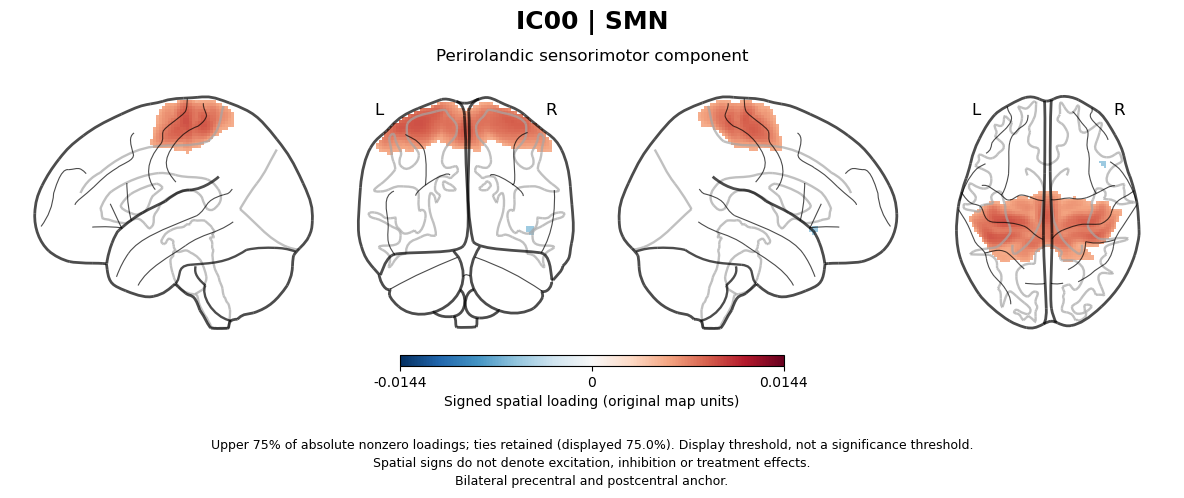

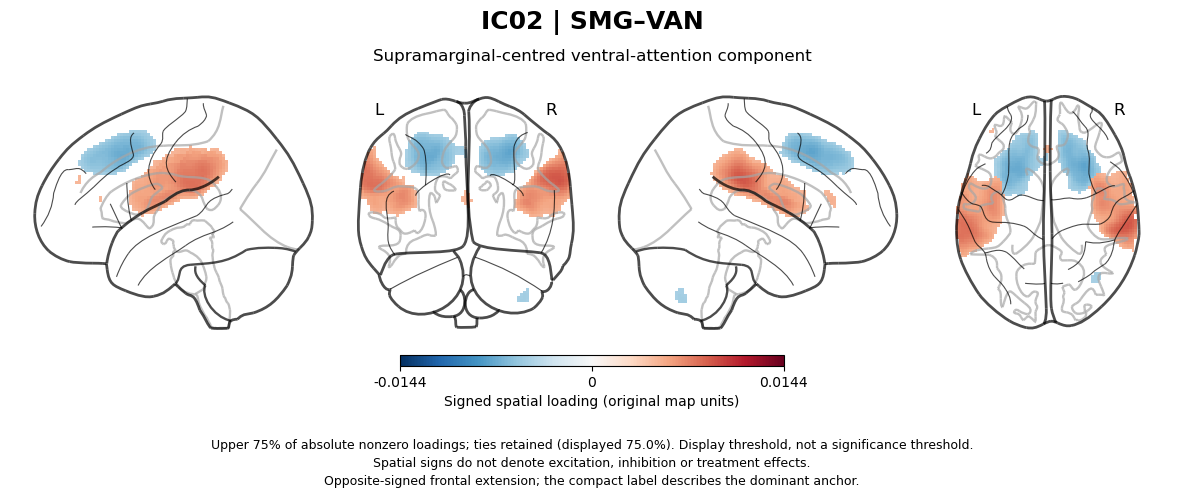

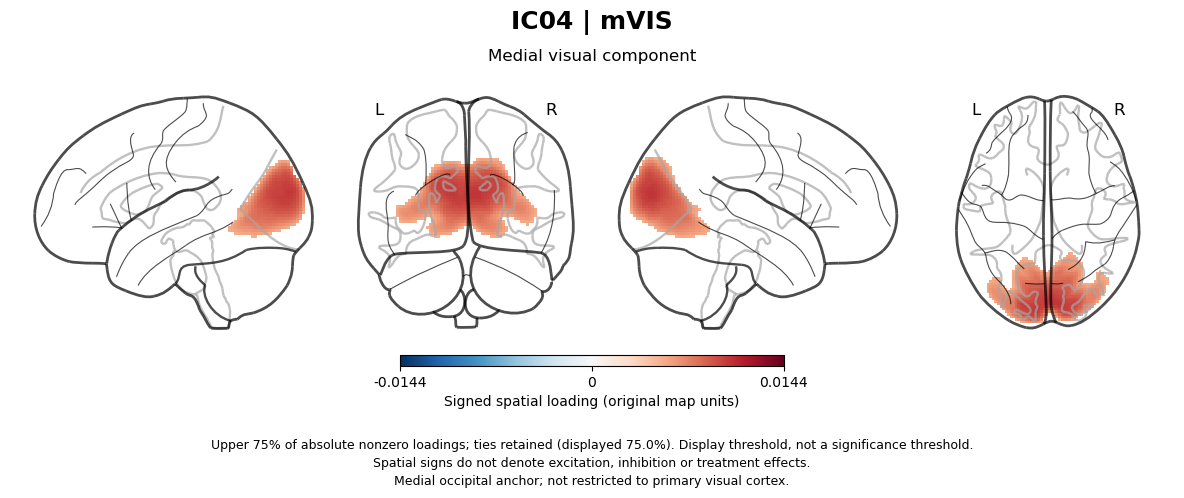

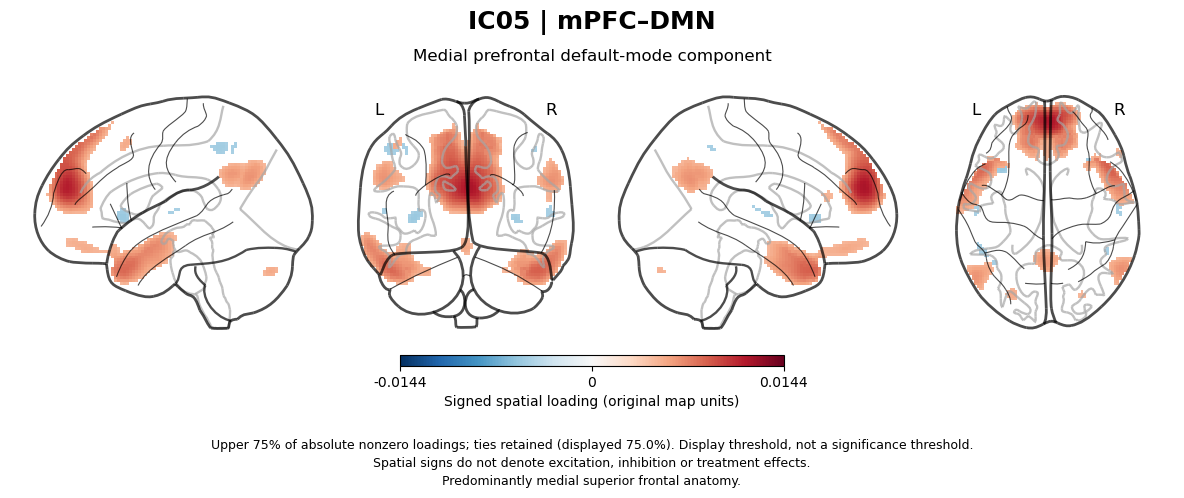

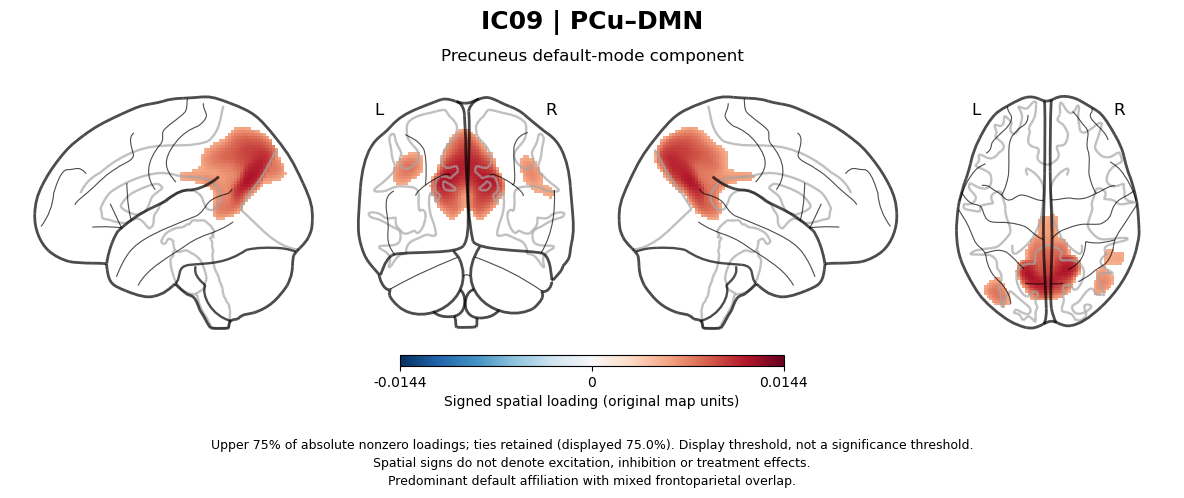

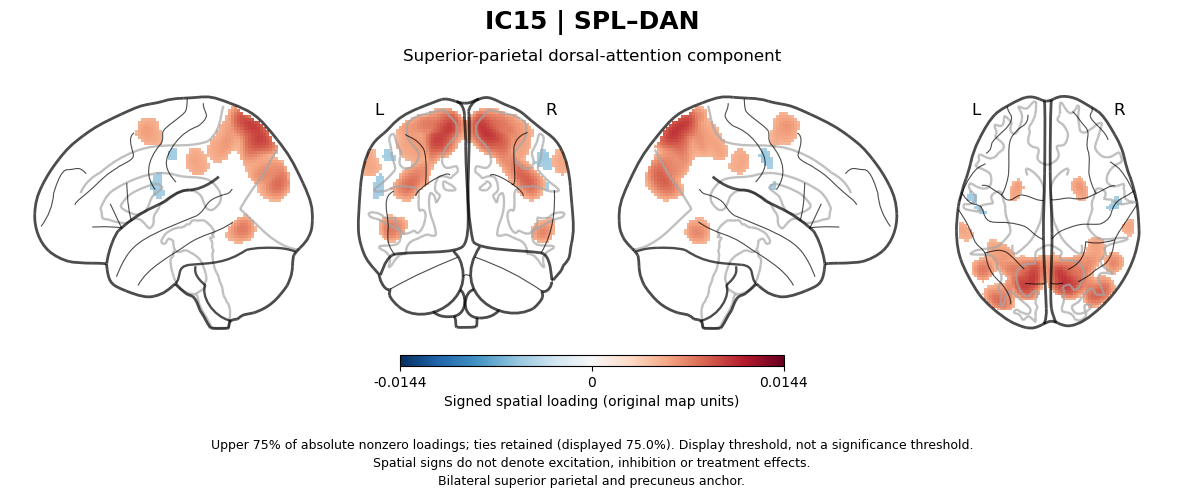

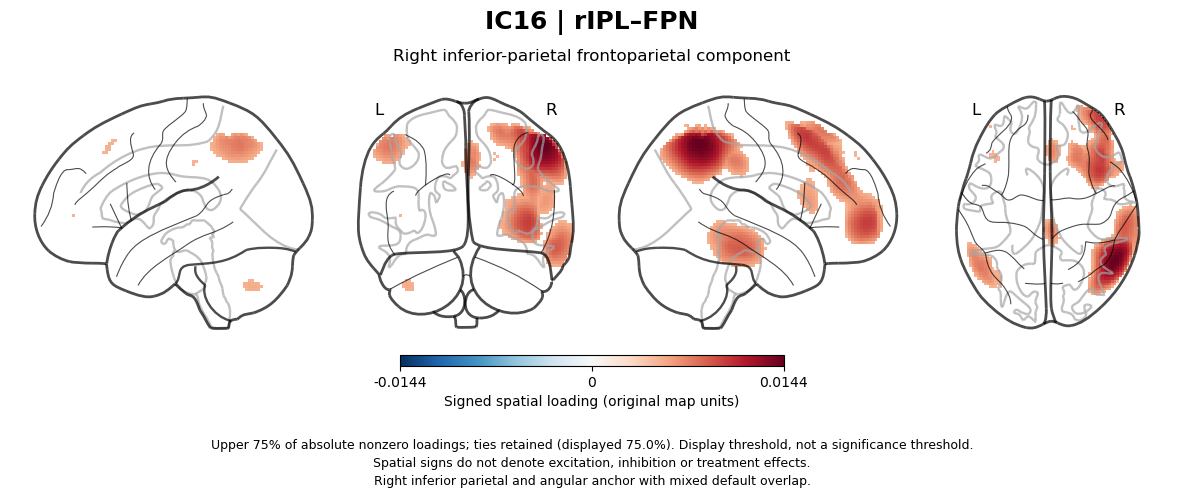

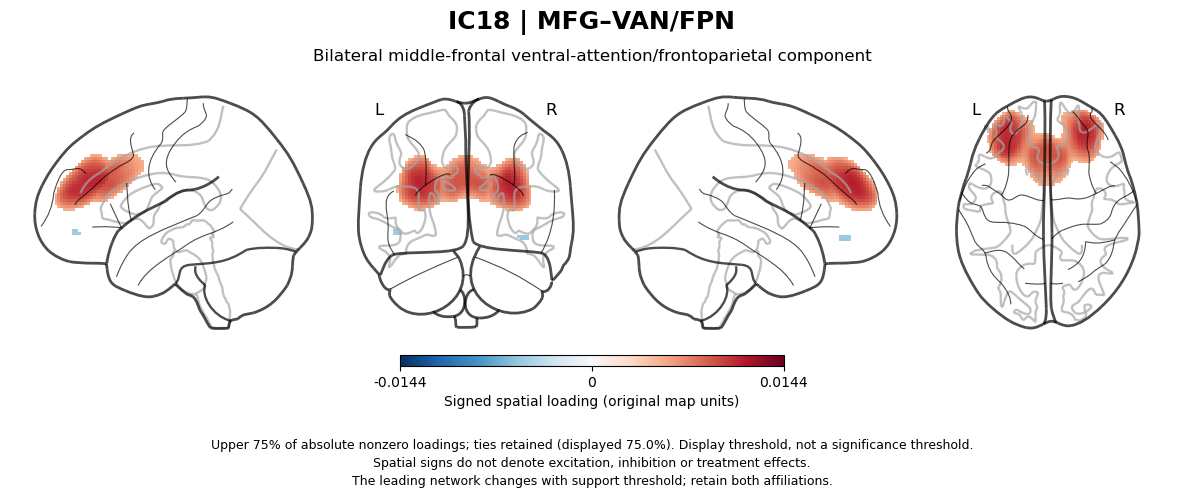

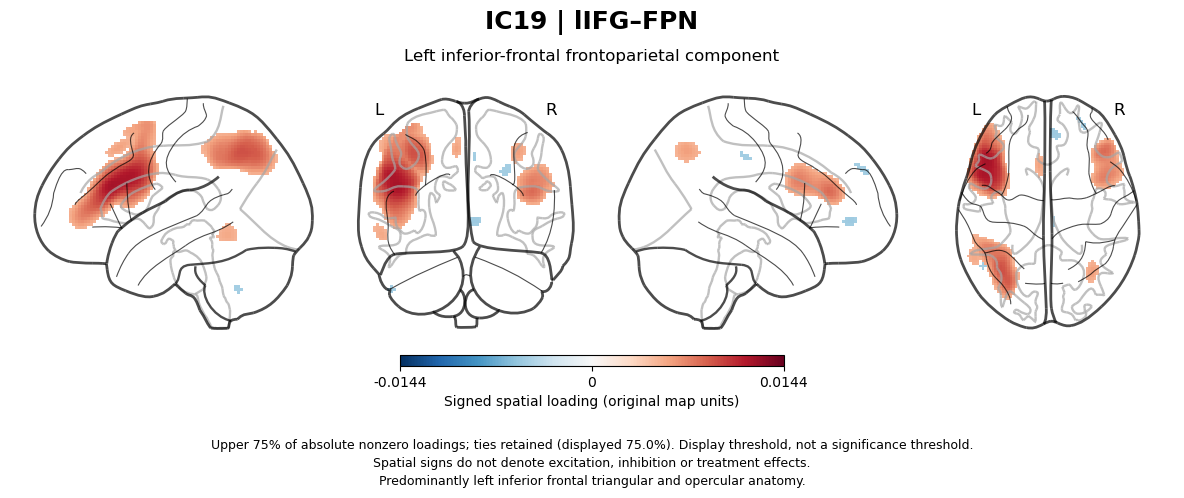

In [7]:
# %% Block 6a: Prepare reusable signed glass-brain functions for the IC descriptions and other figures.
# Method: explicit nonzero-loading percentile and shared colour range; output: plotting helpers.
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from textwrap import fill
from nilearn import image, plotting
from pathlib import Path
import os
import numpy as np

save_figs = 1
# Plotting needs only blocks 1-3 and 5a, not the atlas calculation or an overlap CSV.
valic_ic_dict = {i: image.index_img(ICA_img, i) for i in valid_ic_index}
DISPLAY_PERCENTILE = 25  # Keep the upper 25% of absolute nonzero loadings, including ties.
VMAX_TH = max(float(np.max(np.abs(v.get_fdata()))) for v in valic_ic_dict.values())
custom_cmap2 = 'RdBu_r'
ic_figure_dir = fig_path / 'Section3_ICs' 

def ic_display_map(ic_img, percentile=75):
    values = ic_img.get_fdata()
    absolute = np.abs(values)
    cutoff = float(np.percentile(absolute[absolute > 0], percentile))
    keep = (absolute > 0) & (absolute >= cutoff)
    shown = image.new_img_like(ic_img, np.where(keep, values, 0.0))
    # Mask the zero background without removing any retained loading, including threshold ties.
    zero_mask_threshold = float(absolute[keep].min() / 2)
    retained = float(keep.sum() / np.count_nonzero(absolute))
    return shown, zero_mask_threshold, retained

def draw_ic_map(ic_img, fig, ax, percentile=75, vmax=None, cmap='RdBu_r', views='lyrz'):
    shown, threshold, retained = ic_display_map(ic_img, percentile)
    limit = float(np.max(np.abs(ic_img.get_fdata()))) if vmax is None else float(vmax)
    brain = plotting.plot_glass_brain(
        shown, figure=fig, axes=ax, display_mode=views, plot_abs=False,
        threshold=threshold, resampling_interpolation='nearest', interpolation='nearest',
        cmap=cmap, vmin=-limit, vmax=limit, colorbar=False, black_bg=False, annotate=True)
    return brain, retained

def generate_ic_glass_brain(ic_img, ic_idx, percentile=75, vmax=None, cmap='RdBu_r'):
    names = network_taxonomy[ic_idx]
    limit = float(np.max(np.abs(ic_img.get_fdata()))) if vmax is None else float(vmax)
    fig = plt.figure(figsize=(12, 5.2), facecolor='white')
    ax = fig.add_axes([0.015, 0.34, 0.97, 0.47])
    _, retained = draw_ic_map(ic_img, fig, ax, percentile, limit, cmap)
    fig.text(0.5, 0.965, f"IC{ic_idx:02d} | {names['short']}",
             ha='center', va='top', fontsize=18, fontweight='bold')
    fig.text(0.5, 0.89, names['full'], ha='center', va='top', fontsize=12)
    cax = fig.add_axes([0.34, 0.28, 0.32, 0.021])
    cb = fig.colorbar(ScalarMappable(norm=Normalize(-limit, limit), cmap=cmap),
                      cax=cax, orientation='horizontal', ticks=[-limit, 0, limit])
    cb.ax.xaxis.set_major_formatter(FormatStrFormatter('%.3g'))
    cb.set_label('Signed spatial loading (original map units)', fontsize=10, labelpad=4)
    footer = (f'Upper {100 - percentile:g}% of absolute nonzero loadings; ties retained '
              f'(displayed {100 * retained:.1f}%). Display threshold, not a significance threshold.\n'
              'Spatial signs do not denote excitation, inhibition or treatment effects.\n' +
              fill(names['note'], width=125))
    fig.text(0.5, 0.045, footer, ha='center', va='bottom', fontsize=9, linespacing=1.5)
    return fig

# %% Block 6b: Show each retained IC with its formal name and the revised figure spacing.
# Method: the same top-25% display rule and signed scale for all nine ICs; output: inline figures.
if save_figs:
    ic_figure_dir.mkdir(parents=True, exist_ok=True)

for ic_idx in valid_ic_index:
    fig = generate_ic_glass_brain(valic_ic_dict[ic_idx], ic_idx,
                                  percentile=DISPLAY_PERCENTILE, vmax=VMAX_TH, cmap=custom_cmap2)
    if save_figs:
        stem = f'IC{ic_idx:02d}_p{DISPLAY_PERCENTILE:g}_GlassBrain'
        fig.savefig(ic_figure_dir / f'{stem}.png', dpi=300, facecolor='white')
        fig.savefig(ic_figure_dir / f'{stem}.pdf', facecolor='white')
    plt.show()
    plt.close(fig)

## 3. Customed visualization for presentation

IC00 | SMN


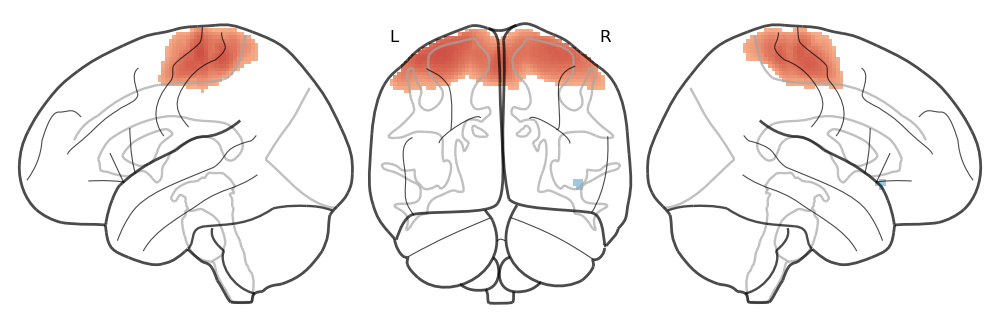

IC02 | SMG–VAN


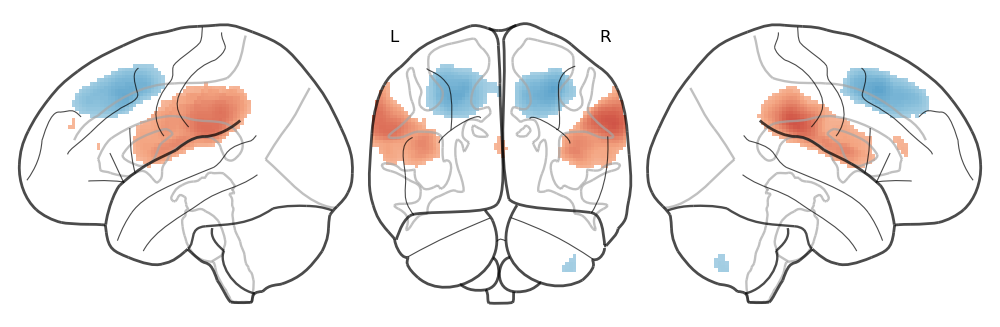

IC18 | MFG–VAN/FPN


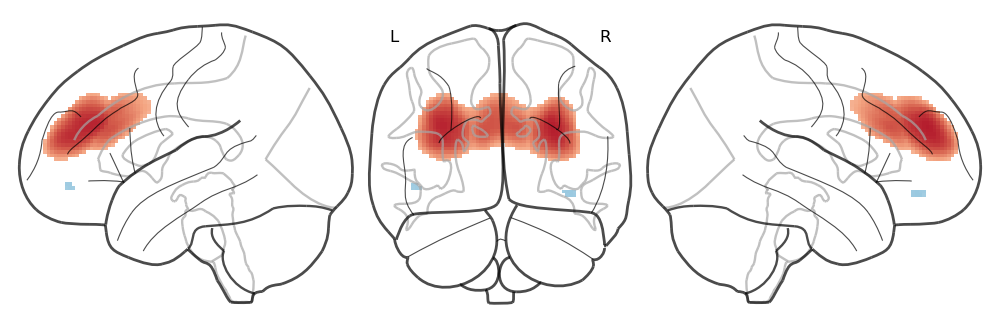

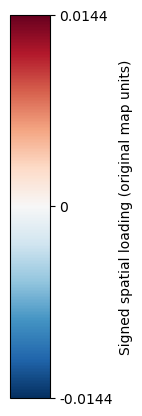

In [8]:
# %% Block 7a: Make standalone transparent IC maps for assembling the EC figures in PowerPoint.
# Method: the same signed support and scale, with optional individual views; output: reusable figures.
save_maps = 0

def generate_standalone_ic_glass_brain(ic_img, threshold_pct='75%', VMAX_=None,
                                      cmap='RdBu_r', views='lyr'):
    percentile = float(str(threshold_pct).rstrip('%'))
    fig = plt.figure(figsize=(10, 3.2), facecolor='none')
    ax = fig.add_axes([0.01, 0.02, 0.98, 0.96], facecolor='none')
    brain, _ = draw_ic_map(ic_img, fig, ax, percentile, VMAX_, cmap, views)
    ax.patch.set_alpha(0)
    for view in brain.axes.values():
        view.ax.patch.set_alpha(0)
    return fig

ppt_ics = [0, 2, 18]  # Nodes of the two focal ECs; use valid_ic_index for all nine.
ppt_dir = ic_figure_dir / 'PPT_maps'
if save_maps:
    ppt_dir.mkdir(parents=True, exist_ok=True)

for ic_idx in ppt_ics:
    fig = generate_standalone_ic_glass_brain(
        valic_ic_dict[ic_idx], threshold_pct=f'{DISPLAY_PERCENTILE:g}%',
        VMAX_=VMAX_TH, cmap=custom_cmap2, views='lyr')
    print(f"IC{ic_idx:02d} | {network_taxonomy[ic_idx]['short']}")
    if save_maps:
        stem = f'IC{ic_idx:02d}_p{DISPLAY_PERCENTILE:g}_transparent'
        fig.savefig(ppt_dir / f'{stem}.png', dpi=300, transparent=True)
        fig.savefig(ppt_dir / f'{stem}.pdf', transparent=True)
    plt.show()
    plt.close(fig)
# views='l', 'r', 'y' or 'z' gives one projection; 'lyrz' gives all four.

# %% Block 7b: Create the separate colour key for the PowerPoint maps.
# Method: identical signed colour range to blocks 6-7; output: one optional transparent colourbar.
fig_cb2, ax_cb2 = plt.subplots(figsize=(2.2, 4.4), facecolor='none')
fig_cb2.subplots_adjust(left=0.18, right=0.36, bottom=0.08, top=0.95)
cb2 = fig_cb2.colorbar(ScalarMappable(norm=Normalize(-VMAX_TH, VMAX_TH), cmap=custom_cmap2),
                       cax=ax_cb2, orientation='vertical', ticks=[-VMAX_TH, 0, VMAX_TH])
cb2.ax.yaxis.set_major_formatter(FormatStrFormatter('%.3g'))
cb2.set_label('Signed spatial loading (original map units)', fontsize=10)
if save_maps:
    fig_cb2.savefig(ppt_dir / 'IC_signed_colorbar.png', dpi=300, transparent=True)
    fig_cb2.savefig(ppt_dir / 'IC_signed_colorbar.pdf', transparent=True)
plt.show()
plt.close(fig_cb2)